# M5 Walmart Forecasting Dataset — Exploratory Data Analysis

**Dataset:** `data/processed/m5_sales.parquet` (Store `CA_1`, 200 balanced SKUs across `FOODS`, `HOBBIES`, and `HOUSEHOLD`, last 2.5 years / 913 days post-`sell_price` NaN filtering).

This notebook generates report-ready summary tables and figures covering:
1. Dataset overview & zero-sales intermittency (%)
2. Category volume & revenue breakdown
3. Weekday seasonality patterns
4. California SNAP benefit lift (`snap_CA`) on `FOODS` vs. other categories
5. `sell_price` distribution across categories

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
parquet_path = repo_root / "data" / "processed" / "m5_sales.parquet"
if not parquet_path.exists():
    parquet_path = repo_root / "data" / "processed" / "sample_sales.parquet"

df = pd.read_parquet(parquet_path)
df["date"] = pd.to_datetime(df["date"])
df["revenue"] = df["sales"].astype(np.float64) * df["sell_price"].astype(np.float64)

print(f"Loaded: {parquet_path.name}")
print(f"Rows: {len(df):,} | SKUs: {df['item_id'].nunique()} | Stores: {df['store_id'].unique().tolist()}")
print(f"Date range: {df['date'].min().date()} -> {df['date'].max().date()} ({df['date'].nunique()} days)")
print(f"Missing sell_price rows: {int(df['sell_price'].isna().sum())}")

Loaded: m5_sales.parquet
Rows: 179,243 | SKUs: 200 | Stores: ['CA_1']
Date range: 2013-10-25 -> 2016-04-24 (913 days)
Missing sell_price rows: 0


## 1. Zero-Sales Intermittency & Count Distribution

Daily retail SKU sales are zero-inflated and right-skewed, which motivates using LightGBM with `objective="tweedie"` rather than Gaussian MSE.

Overall Zero-Sales Day Share: 54.51%


,cat_id,skus,observations,zero_sales_pct,mean_daily_units,p95_daily_units,max_daily_units
0,FOODS,67,60938,53.01,1.664,7.0,59
1,HOBBIES,67,60179,60.64,1.346,6.0,75
2,HOUSEHOLD,66,58126,49.73,1.252,5.0,28


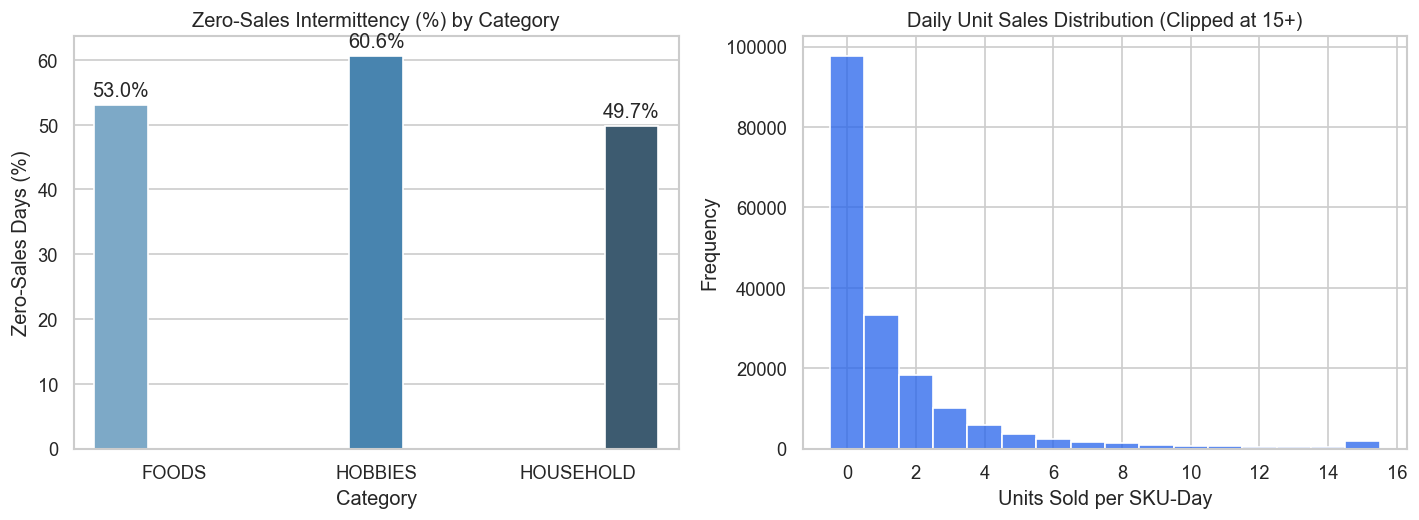

In [2]:
overall_zero_pct = 100.0 * (df["sales"] == 0).mean()
intermittency_tbl = (
    df.groupby("cat_id", observed=True)
    .agg(
        skus=("item_id", "nunique"),
        observations=("sales", "count"),
        zero_sales_pct=("sales", lambda s: round(100.0 * (s == 0).mean(), 2)),
        mean_daily_units=("sales", lambda s: round(float(s.mean()), 3)),
        p95_daily_units=("sales", lambda s: round(float(np.percentile(s, 95)), 2)),
        max_daily_units=("sales", "max"),
    )
    .reset_index()
)
print(f"Overall Zero-Sales Day Share: {overall_zero_pct:.2f}%")
display(intermittency_tbl)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=intermittency_tbl, x="cat_id", y="zero_sales_pct", hue="cat_id", legend=False, palette="Blues_d", ax=axes[0])
axes[0].set_title("Zero-Sales Intermittency (%) by Category")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Zero-Sales Days (%)")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=3)

clipped_sales = df["sales"].clip(upper=15)
sns.histplot(clipped_sales, bins=16, discrete=True, color="#2563eb", ax=axes[1])
axes[1].set_title("Daily Unit Sales Distribution (Clipped at 15+)")
axes[1].set_xlabel("Units Sold per SKU-Day")
axes[1].set_ylabel("Frequency")
plt.tight_layout()
plt.show()

## 2. Category Volume & Revenue Breakdown

,cat_id,skus,total_units,total_revenue,avg_sell_price,unit_share_pct,revenue_share_pct
0,FOODS,67,101428,227705.14,3.17,39.75,27.65
1,HOBBIES,67,81008,225001.44,6.02,31.74,27.32
2,HOUSEHOLD,66,72760,370735.11,6.00,28.51,45.02


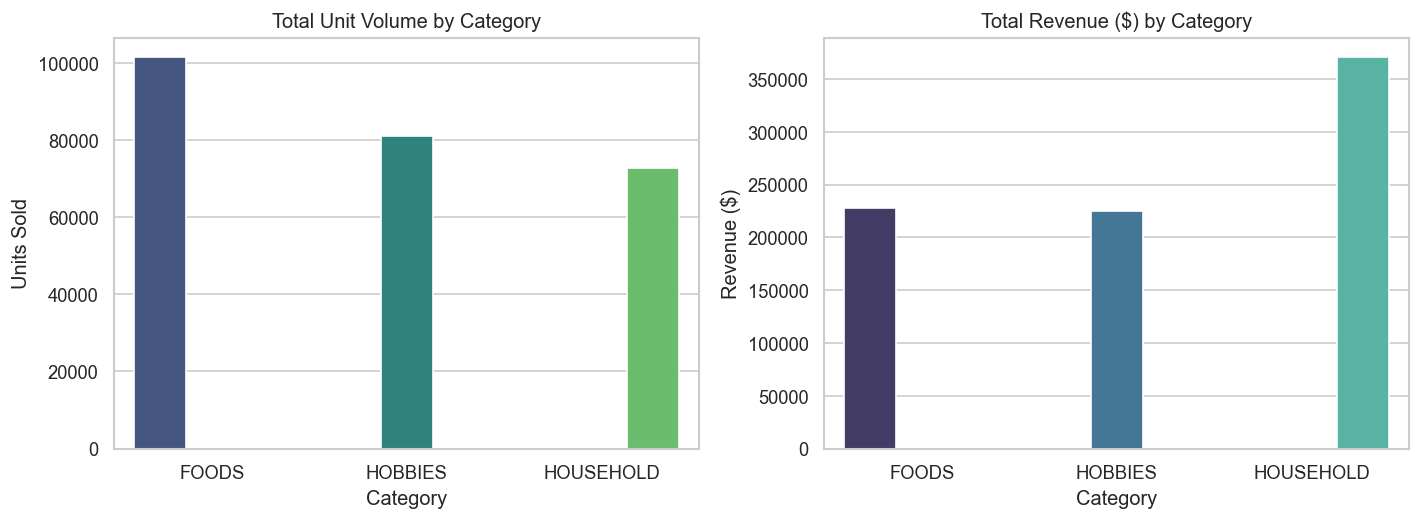

In [3]:
cat_summary = (
    df.groupby("cat_id", observed=True)
    .agg(
        skus=("item_id", "nunique"),
        total_units=("sales", "sum"),
        total_revenue=("revenue", "sum"),
        avg_sell_price=("sell_price", "mean"),
    )
    .reset_index()
    .sort_values("total_units", ascending=False)
)
cat_summary["unit_share_pct"] = (100.0 * cat_summary["total_units"] / cat_summary["total_units"].sum()).round(2)
cat_summary["revenue_share_pct"] = (100.0 * cat_summary["total_revenue"] / cat_summary["total_revenue"].sum()).round(2)
cat_summary["total_revenue"] = cat_summary["total_revenue"].round(2)
cat_summary["avg_sell_price"] = cat_summary["avg_sell_price"].round(2)
display(cat_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=cat_summary, x="cat_id", y="total_units", hue="cat_id", legend=False, palette="viridis", ax=axes[0])
axes[0].set_title("Total Unit Volume by Category")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Units Sold")

sns.barplot(data=cat_summary, x="cat_id", y="total_revenue", hue="cat_id", legend=False, palette="mako", ax=axes[1])
axes[1].set_title("Total Revenue ($) by Category")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Revenue ($)")
plt.tight_layout()
plt.show()

## 3. Weekday Seasonality Patterns

cat_id,FOODS,HOBBIES,HOUSEHOLD
weekday_name,,,
Monday,1.539,1.281,1.265
Tuesday,1.433,1.185,1.050
Wednesday,1.433,1.196,0.992
Thursday,1.508,1.207,0.972
Friday,1.821,1.385,1.156
Saturday,2.063,1.661,1.604
Sunday,1.848,1.503,1.719


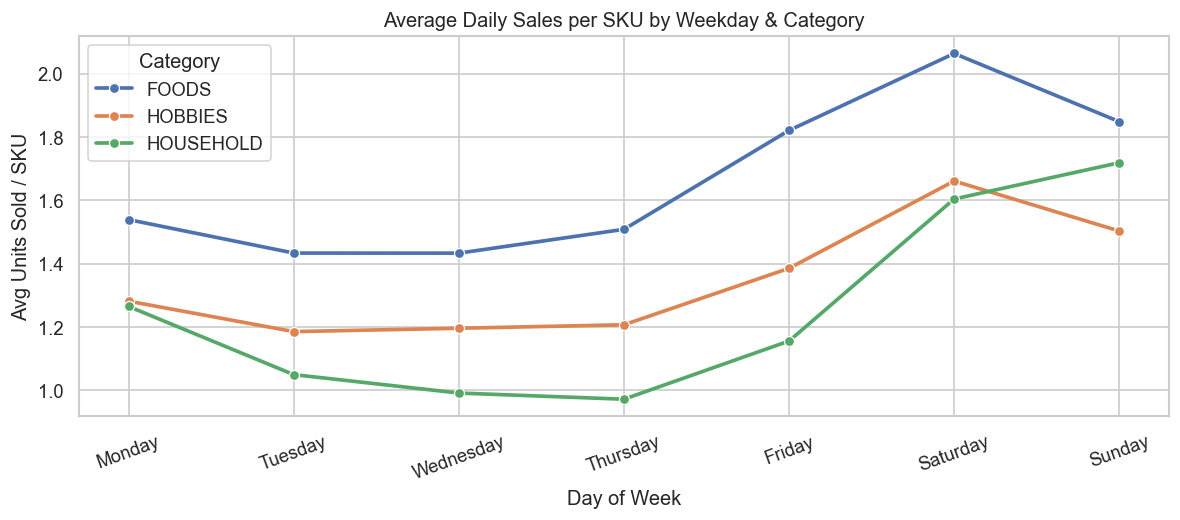

In [4]:
wd_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["weekday_name"] = pd.Categorical(df["date"].dt.day_name(), categories=wd_order, ordered=True)

wd_tbl = (
    df.groupby(["weekday_name", "cat_id"], observed=True)["sales"]
    .mean()
    .reset_index(name="avg_daily_units")
)
wd_pivot = wd_tbl.pivot(index="weekday_name", columns="cat_id", values="avg_daily_units").round(3)
display(wd_pivot)

plt.figure(figsize=(10, 4.5))
sns.lineplot(data=wd_tbl, x="weekday_name", y="avg_daily_units", hue="cat_id", marker="o", linewidth=2.2)
plt.title("Average Daily Sales per SKU by Weekday & Category")
plt.xlabel("Day of Week")
plt.ylabel("Avg Units Sold / SKU")
plt.xticks(rotation=20)
plt.legend(title="Category")
plt.tight_layout()
plt.show()

## 4. California SNAP Benefit Lift (`snap_CA`) on `FOODS` vs. Non-`FOODS`

snap_CA,Non_SNAP_Avg,SNAP_Avg,Lift_Pct
cat_id,,,
FOODS,1.6628,1.6678,0.30
HOBBIES,1.3154,1.4089,7.10
HOUSEHOLD,1.2306,1.2950,5.24


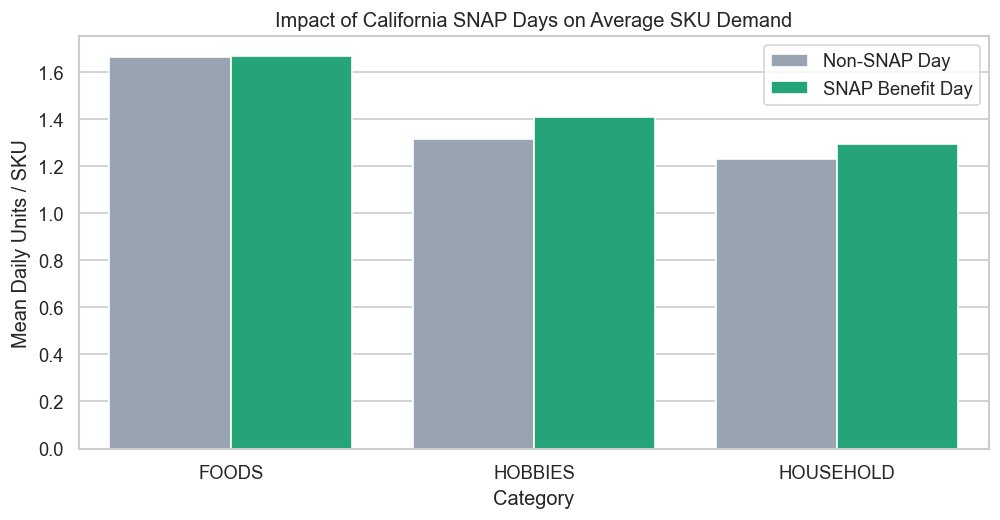

In [5]:
snap_tbl = (
    df.groupby(["cat_id", "snap_CA"], observed=True)["sales"]
    .mean()
    .unstack("snap_CA")
    .rename(columns={0: "Non_SNAP_Avg", 1: "SNAP_Avg"})
)
snap_tbl["Lift_Pct"] = (100.0 * (snap_tbl["SNAP_Avg"] - snap_tbl["Non_SNAP_Avg"]) / snap_tbl["Non_SNAP_Avg"]).round(2)
snap_tbl = snap_tbl.round(4)
display(snap_tbl)

snap_plot = df.groupby(["cat_id", "snap_CA"], observed=True)["sales"].mean().reset_index()
snap_plot["SNAP_Day"] = snap_plot["snap_CA"].map({0: "Non-SNAP Day", 1: "SNAP Benefit Day"})

plt.figure(figsize=(8.5, 4.5))
sns.barplot(data=snap_plot, x="cat_id", y="sales", hue="SNAP_Day", palette=["#94a3b8", "#10b981"])
plt.title("Impact of California SNAP Days on Average SKU Demand")
plt.xlabel("Category")
plt.ylabel("Mean Daily Units / SKU")
plt.legend(title="")
plt.tight_layout()
plt.show()

## 5. `sell_price` Distribution Across Categories

,min_price,p25,median_price,mean_price,p75,max_price
cat_id,,,,,,
FOODS,0.98,1.96,2.68,3.17,3.98,9.980000
HOBBIES,0.46,1.77,4.64,6.02,8.56,30.980000
HOUSEHOLD,0.97,2.97,4.63,6.00,6.97,29.969999


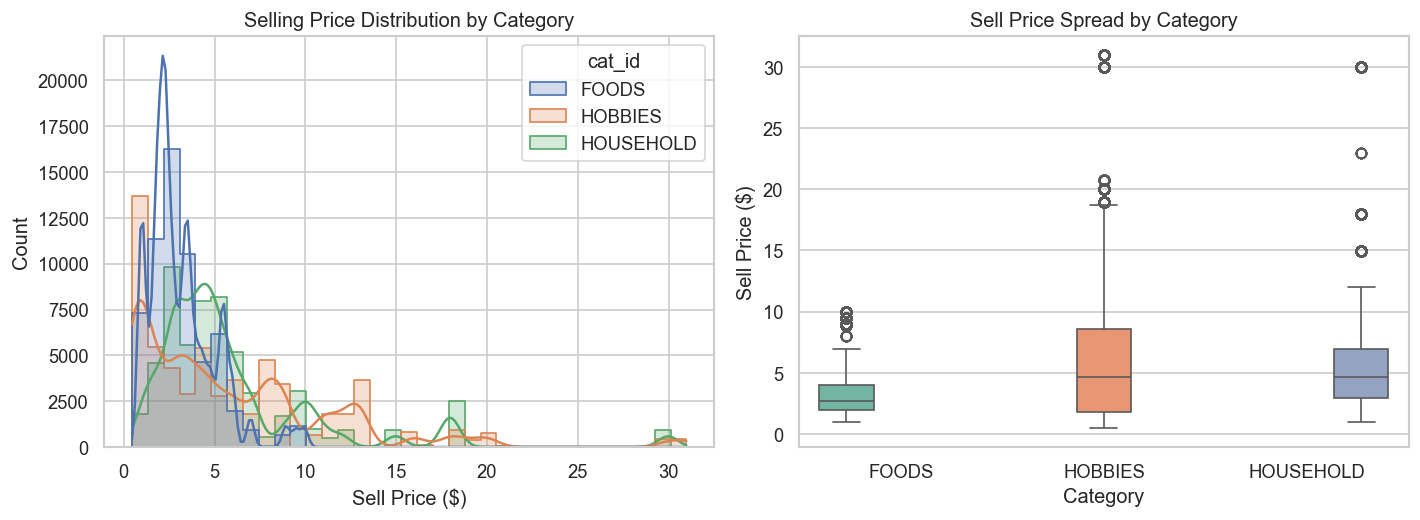

In [6]:
price_stats = (
    df.groupby("cat_id", observed=True)["sell_price"]
    .agg(
        min_price="min",
        p25=lambda s: float(np.percentile(s, 25)),
        median_price="median",
        mean_price="mean",
        p75=lambda s: float(np.percentile(s, 75)),
        max_price="max",
    )
    .round(2)
)
display(price_stats)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(data=df, x="sell_price", hue="cat_id", bins=35, kde=True, element="step", ax=axes[0])
axes[0].set_title("Selling Price Distribution by Category")
axes[0].set_xlabel("Sell Price ($)")

sns.boxplot(data=df, x="cat_id", y="sell_price", hue="cat_id", legend=False, palette="Set2", ax=axes[1])
axes[1].set_title("Sell Price Spread by Category")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Sell Price ($)")
plt.tight_layout()
plt.show()